# Ridge Regression: Disease Progression with Correlated Predictors

**Family:** Supervised learning | **Level:** Intermediate | **Dataset:** `diabetes` | **Runs on:** CPU, about 1 minute(s)

Shrink coefficients with an L2 penalty and watch the bias variance trade-off on diabetes data.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- What the L2 penalty does to coefficients
- Why scaling matters before penalised regression
- How to read a coefficient path

**Prerequisites:**

- Linear regression notebook
- Train, validation and test splits

**Skills you will have afterwards:**

- Choose a hyperparameter on validation data
- Compare with a baseline
- Run a sensitivity experiment

## 2. Real-World Problem

**Context.** Clinical studies measure many correlated blood markers per patient.

**The problem.** Predict a quantitative measure of diabetes progression one year after baseline from ten baseline features.

**Why it matters.** Stable and accurate risk scores help target follow up, and unstable coefficients make a score untrustworthy.

**Why machine learning.** Markers interact and no closed form biological model is available.

**Why this algorithm.** The serum measures are strongly correlated, which is exactly where ridge stabilises least squares.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Ridge Regression: Biased Estimation for Nonorthogonal Problems

- **Type:** foundational paper
- **Authors:** Hoerl, A. E. and Kennard, R. W.
- **Year and venue:** 1970, Technometrics 12(1):55-67
- **DOI or URL:** https://doi.org/10.1080/00401706.1970.10488634
- **Verification:** Crossref 2026-11-17
- **Research objective:** Stabilise least squares when predictors are nearly collinear.
- **Methodology:** Add a multiple of the identity to X'X before inversion.
- **Dataset:** Illustrative examples.
- **Main findings:** A small bias can cut the variance and the mean squared error of coefficients.
- **Limitations:** Keeps every predictor, so it does not select variables.

### Least angle regression

- **Type:** foundational paper
- **Authors:** Efron, B., Hastie, T., Johnstone, I. and Tibshirani, R.
- **Year and venue:** 2004, The Annals of Statistics 32(2):407-499
- **DOI or URL:** https://doi.org/10.1214/009053604000000067
- **Verification:** Crossref 2026-11-17
- **Research objective:** Give an efficient path algorithm for the lasso and related methods.
- **Methodology:** Move coefficients along the direction equiangular to the active predictors.
- **Dataset:** The diabetes progression data of 442 patients used in this repository.
- **Main findings:** The full lasso path costs about the same as one least squares fit.
- **Limitations:** Sensitive to noise when predictors are strongly correlated.

**Relationship to this notebook.** Hoerl and Kennard introduce ridge for nearly collinear predictors. Efron et al. use the same diabetes data (442 patients) to introduce least angle regression, so the data matches the literature in structure, though not the exact protocol. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Objective.**

$$\hat\beta^{\text{ridge}} = \arg\min_\beta \; \lVert y - A\beta \rVert_2^2 + \lambda \lVert \beta \rVert_2^2, \qquad \lambda \ge 0$$

The intercept is not penalised.

**Closed form.** $\hat\beta = (X^\top X + \lambda I)^{-1} X^\top y$. Adding $\lambda I$ makes the matrix invertible even when $X^\top X$ is nearly singular.

**Effect.** In the SVD basis, each component is shrunk by $d_j^2 / (d_j^2 + \lambda)$, so directions of low variance are shrunk most.

**Assumptions.** Same as least squares, plus standardised features so that the penalty treats them equally.

**Limitations.** Never sets a coefficient exactly to zero, so it does not select features. $\lambda$ must be tuned.

## 5. Dataset Introduction

**Diabetes progression** from Efron, Hastie, Johnstone and Tibshirani (2004), shipped with scikit-learn. 442 patients, 10 baseline features (`age`, `sex`, `bmi`, `bp`, and six blood serum measures `s1` to `s6`), target is a quantitative measure of disease progression one year after baseline. The provider centred and scaled the features. Data terms of the original source are not stated by the provider. Limits: small sample, no time dimension, `sex` is a standardised number.

The table printed below the next cell comes from the dataset registry in `src/ml_lab/data/registry.py`. Licence terms belong to the data provider, not to this repository.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from ml_lab.data import load_dataset, missing_report
from ml_lab.preprocessing import split_three_way, build_preprocessor, make_model_pipeline, feature_names
from ml_lab.evaluation import evaluate_estimator, compare_models
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "ridge_regression"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("diabetes")
data = bundle.frame
TASK = bundle.task
TARGET = bundle.target
print("task:", TASK, "| target:", TARGET, "| shape:", data.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())
display(data.head())

task: regression | target: progression | shape: (442, 11)


,source
title,Diabetes disease progression
source,"Efron, Hastie, Johnstone, Tibshirani (2004), L..."
url,https://www4.stat.ncsu.edu/~boos/var.select/di...
license,distributed with scikit-learn (BSD-3-Clause pa...
doi,None
rows,442
features,10
limits,Features are mean centred and scaled by the pr...


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 6. Exploratory Data Analysis

We look at size, types, missing values, the target, feature distributions, correlation and outliers before any modelling. 

In [3]:
print("Rows and columns:", data.shape)
display(data.dtypes.value_counts().rename("columns by dtype").to_frame())
display(data.describe().T.round(3).head(20))
missing = missing_report(data)
print("Columns with missing values:", len(missing))
display(missing)
print("Duplicate rows:", int(data.duplicated().sum()))

Rows and columns: (442, 11)


,columns by dtype
float64,11


,count,mean,std,min,25%,50%,75%,max
age,442.0,-0.000,0.048,-0.107,-0.037,0.005,0.038,0.111
sex,442.0,0.000,0.048,-0.045,-0.045,-0.045,0.051,0.051
bmi,442.0,-0.000,0.048,-0.090,-0.034,-0.007,0.031,0.171
bp,442.0,-0.000,0.048,-0.112,-0.037,-0.006,0.036,0.132
s1,442.0,-0.000,0.048,-0.127,-0.034,-0.004,0.028,0.154
s2,442.0,0.000,0.048,-0.116,-0.030,-0.004,0.030,0.199
s3,442.0,-0.000,0.048,-0.102,-0.035,-0.007,0.029,0.181
s4,442.0,-0.000,0.048,-0.076,-0.039,-0.003,0.034,0.185
s5,442.0,0.000,0.048,-0.126,-0.033,-0.002,0.032,0.134
s6,442.0,0.000,0.048,-0.138,-0.033,-0.001,0.028,0.136


Columns with missing values: 0


,missing,percent


Duplicate rows: 0


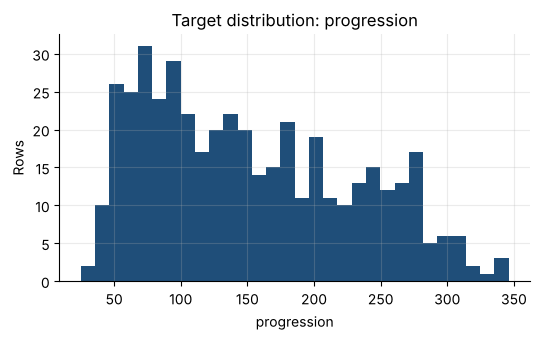

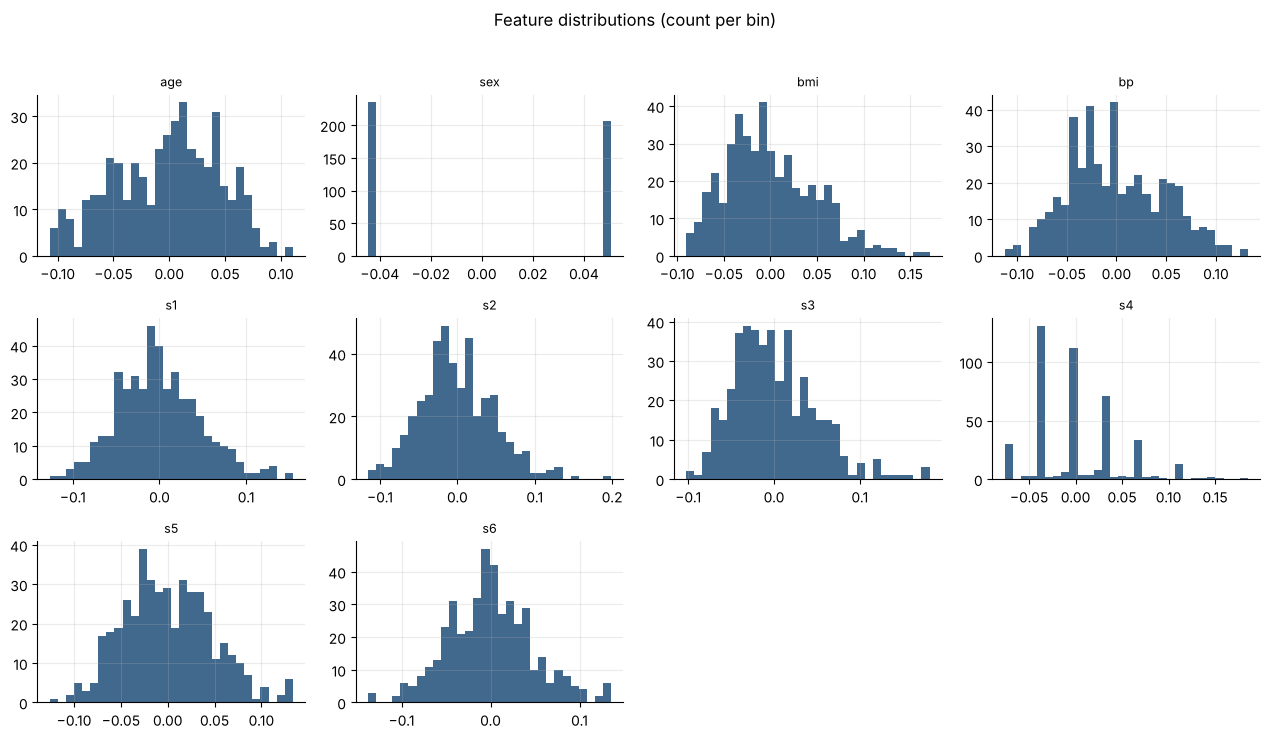

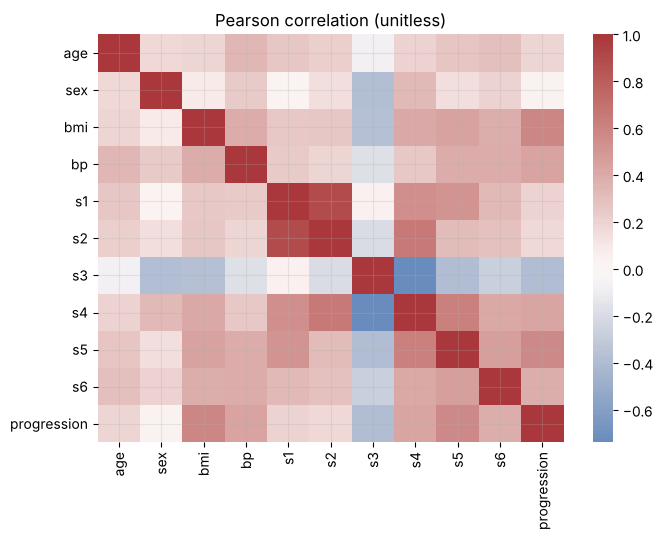

,feature,outliers,percent
0,s6,9,2.04
1,s1,8,1.81
2,s3,7,1.58
3,s2,7,1.58
4,s5,4,0.90
5,bmi,3,0.68
6,s4,2,0.45
7,age,0,0.00


In [4]:
fig = viz.plot_target(data[TARGET], TASK)
plt.show()
fig = viz.plot_distributions(data.drop(columns=[TARGET]))
plt.show()
fig = viz.plot_correlation(data)
plt.show()
display(viz.outlier_table(data.drop(columns=[TARGET])).head(8))

## 7. Data Preprocessing

Rules used here:

- Split first, then fit imputers, scalers and encoders on the training rows only. This prevents data leakage.
- The test set is touched once, at the end.
- Order inside the pipeline: impute, scale or encode, then model.


In [5]:

X, y = data.drop(columns=[TARGET]), data[TARGET]
X_train, X_val, X_test, y_train, y_val, y_test = split_three_way(X, y, task=TASK, seed=SEED)
print("train / validation / test rows:", len(X_train), len(X_val), len(X_test))
if TASK == "classification":
    split_rates = pd.DataFrame({"train": y_train.value_counts(normalize=True),
                                "validation": y_val.value_counts(normalize=True),
                                "test": y_test.value_counts(normalize=True)}).round(3)
    display(split_rates)
prep = build_preprocessor(X_train, scale=True, encode="onehot")
Xtr = prep.fit_transform(X_train)   # fit on train only
Xva, Xte = prep.transform(X_val), prep.transform(X_test)
print("transformed train shape:", Xtr.shape)

train / validation / test rows: 264 89 89
transformed train shape: (264, 10)


## 8. Algorithm Implementation

### 8.1 Concept

Ridge trades a little bias for a large drop in variance. As $\lambda$ grows all coefficients move smoothly toward zero.

### 8.2 Python implementation from scratch

The closed form is short, so we implement it and compare with scikit-learn.

In [6]:
ytr = y_train.values

def ridge_fit(X, y, alpha):
    A = np.c_[np.ones(len(X)), X]
    penalty = alpha * np.eye(A.shape[1])
    penalty[0, 0] = 0                      # keep intercept free
    return np.linalg.solve(A.T @ A + penalty, A.T @ y)

mine = ridge_fit(Xtr, ytr, alpha=10.0)
reference = Ridge(alpha=10.0).fit(Xtr, ytr)
print("max coefficient gap vs sklearn:", np.abs(mine[1:] - reference.coef_).max())

max coefficient gap vs sklearn: 2.184918912462308e-13


### 8.3 Library implementation

The estimator is wrapped in a pipeline so imputation, scaling and encoding are fitted on training rows only.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `alpha` | Penalty strength $\lambda$. Larger means more shrinkage. |
| `solver` | Numerical method. `auto` is fine here. |

## 9. Model Training

Procedure: fit on the training rows, choose one hyperparameter on the validation rows, refit on training plus validation, then evaluate once on the test rows. The random seed is fixed (`SEED = 42`). 

In [7]:
SELECT = "RMSE"
LOWER_IS_BETTER = True
SCORING = "neg_root_mean_squared_error"
SWEEP_PARAM = "model__alpha"
SWEEP_VALUES = [0.001, 0.01, 0.1, 1, 3, 10, 30, 100]

def build_pipeline():
    return make_model_pipeline(X_train, Ridge(alpha=1.0), scale=True, encode="onehot")

pipe = build_pipeline()
print(pipe.named_steps["model"])
rows = []
for value in SWEEP_VALUES:
    candidate = clone(pipe).set_params(**{SWEEP_PARAM: value}).fit(X_train, y_train)
    rows.append({SWEEP_PARAM: value, **evaluate_estimator(candidate, X_val, y_val, TASK)})
sweep = pd.DataFrame(rows).set_index(SWEEP_PARAM)
display(sweep[[c for c in [SELECT, "R2", "MAE", "Accuracy", "F1", "ROC_AUC", "PR_AUC"] if c in sweep.columns]].round(4))
best_value = sweep[SELECT].idxmin() if LOWER_IS_BETTER else sweep[SELECT].idxmax()
print("best", SWEEP_PARAM, "on validation:", best_value)
final_model = clone(pipe).set_params(**{SWEEP_PARAM: best_value})
X_trainval, y_trainval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
final_model.fit(X_trainval, y_trainval)   # refit before test
print("refit on train plus validation rows")

Ridge()


,RMSE,R2,MAE
model__alpha,,,
0.001,51.1935,0.5217,42.9385
0.010,51.1916,0.5217,42.9353
0.100,51.1741,0.5220,42.9064
1.000,51.1031,0.5233,42.7230
3.000,51.1088,0.5232,42.5927
10.000,51.1605,0.5223,42.6197
30.000,51.2197,0.5212,42.7382
100.000,51.7369,0.5114,43.4323


best model__alpha on validation: 1.0
refit on train plus validation rows


## 10. Evaluation

Regression metrics: MAE (average absolute error in target units), RMSE (square root of the mean squared error, same unit, punishes large errors), R-squared (share of variance explained, can be negative on new data) and MAPE when the target is never zero.

A dummy model gives the floor every real model must beat.

In [8]:
baseline = DummyRegressor(strategy="mean") if TASK == "regression" else DummyClassifier(strategy="prior")
baseline = make_model_pipeline(X_train, baseline, scale=False).fit(X_trainval, y_trainval)
test_metrics = evaluate_estimator(final_model, X_test, y_test, TASK)
baseline_metrics = evaluate_estimator(baseline, X_test, y_test, TASK)
print("Test set, scored once after model choice")
display(compare_models({"baseline": baseline_metrics, "Ridge": test_metrics}))
cv = cross_validate(final_model, X_trainval, y_trainval, cv=5, scoring=SCORING, n_jobs=1)
cv_scores = cv["test_score"]
print(f"5-fold CV {SCORING}: mean {cv_scores.mean():.4f}, std {cv_scores.std(ddof=1):.4f}")
record = ExperimentRecord(notebook=NOTEBOOK_ID, family="supervised", algorithm="Ridge", dataset="diabetes",
                          task=TASK, seed=SEED, config={"param": SWEEP_PARAM, "value": str(best_value)},
                          metrics={k: float(v) for k, v in test_metrics.items()},
                          extra={"baseline": {k: float(v) for k, v in baseline_metrics.items()},
                                 "cv_mean": float(cv_scores.mean()), "cv_std": float(cv_scores.std(ddof=1)),
                                 "cv_scoring": SCORING, "select_metric": SELECT})
print("saved", record.save().name)

Test set, scored once after model choice


,MAE,MSE,RMSE,R2,MAPE_percent
baseline,64.0065,5361.5335,73.2225,-0.0120,62.7918
Ridge,42.8120,2892.0146,53.7775,0.4541,37.4482


5-fold CV neg_root_mean_squared_error: mean -55.0069, std 4.1514
saved ridge_regression.json


## 11. Visualization

All plots use the test rows unless the title says otherwise.

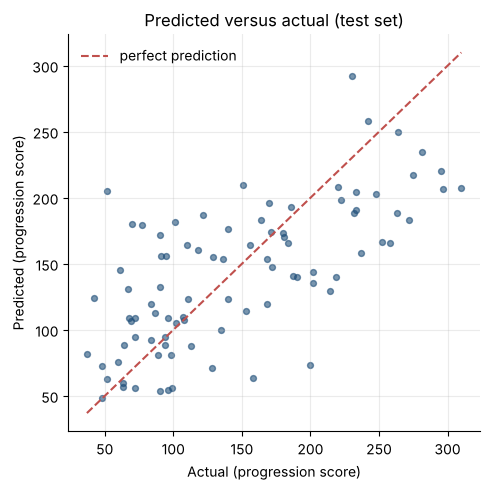

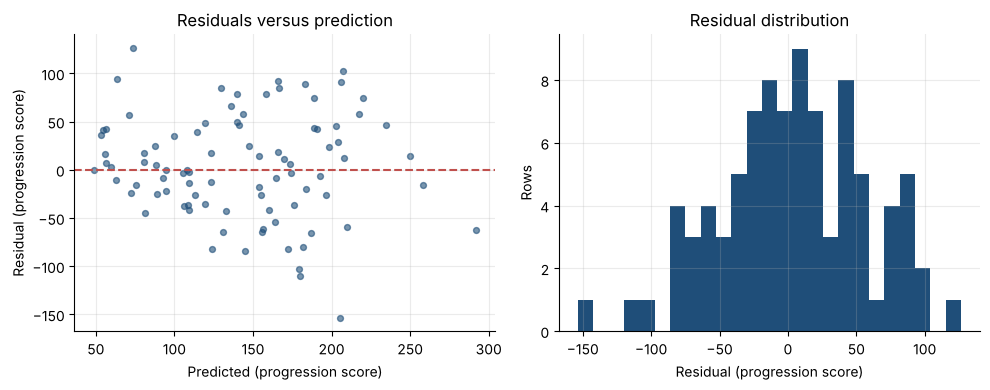

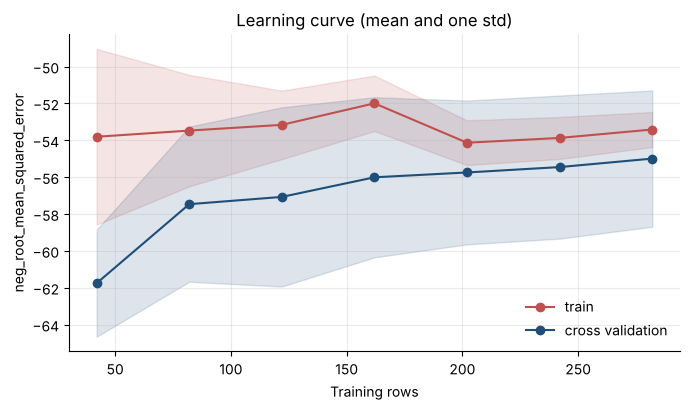

In [9]:
pred = final_model.predict(X_test)
fig = viz.plot_pred_vs_actual(y_test, pred, unit="(progression score)")
save_figure(fig, NOTEBOOK_ID, "pred_vs_actual"); plt.show()
fig = viz.plot_residuals(y_test, pred, unit="(progression score)")
save_figure(fig, NOTEBOOK_ID, "residuals"); plt.show()
fig = viz.plot_learning_curve(final_model, X_trainval, y_trainval, scoring=SCORING)
save_figure(fig, NOTEBOOK_ID, "learning_curve"); plt.show()

## 12. Interpretation

Permutation importance shuffles one feature and measures how much the error grows. Correlated features share importance, so read it as a ranking of groups. Check the residual plot for curvature or funnel shapes, which mean the model misses structure or the error variance changes with the prediction.

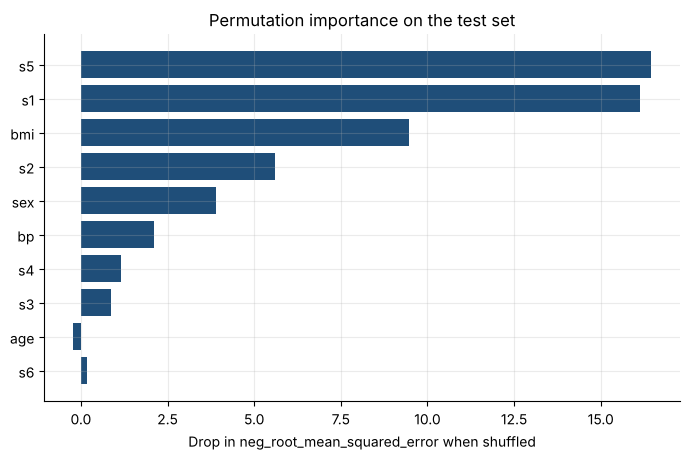

Top features: s5, s1, bmi, s2, sex
Largest test errors:


,actual,predicted,abs_error
56,52.0,205.386,153.386
77,200.0,73.592,126.408
211,70.0,179.958,109.958
9,310.0,207.270,102.730
209,77.0,179.446,102.446



Test RMSE: 53.7775 | baseline RMSE: 73.2225
Cross validation spread (std): 4.1514. A test gap larger than this spread is meaningful.


In [10]:
perm = permutation_importance(final_model, X_test, y_test, scoring=SCORING, n_repeats=10, random_state=SEED)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
fig = viz.plot_importance(importance.index, importance.values, title="Permutation importance on the test set",
                          top=12, xlabel="Drop in " + SCORING + " when shuffled")
save_figure(fig, NOTEBOOK_ID, "importance"); plt.show()
print("Top features:", ", ".join(importance.index[:5]))
errors = (y_test.values - final_model.predict(X_test)) if TASK == "regression" else (y_test.values != final_model.predict(X_test))
if TASK == "regression":
    worst = pd.DataFrame({"actual": y_test.values, "predicted": final_model.predict(X_test)}, index=y_test.index)
    worst["abs_error"] = (worst["actual"] - worst["predicted"]).abs()
    print("Largest test errors:")
    display(worst.sort_values("abs_error", ascending=False).head(5).round(3))
else:
    print("Misclassified test rows:", int(errors.sum()), "of", len(errors))
print()
print(f"Test {SELECT}: {test_metrics[SELECT]:.4f} | baseline {SELECT}: {baseline_metrics[SELECT]:.4f}")
print(f"Cross validation spread (std): {cv_scores.std(ddof=1):.4f}. A test gap larger than this spread is meaningful.")

## 13. Experiments and Challenges

### Experiment 1: Coefficient path

Plot every coefficient against $\lambda$ on a log axis.

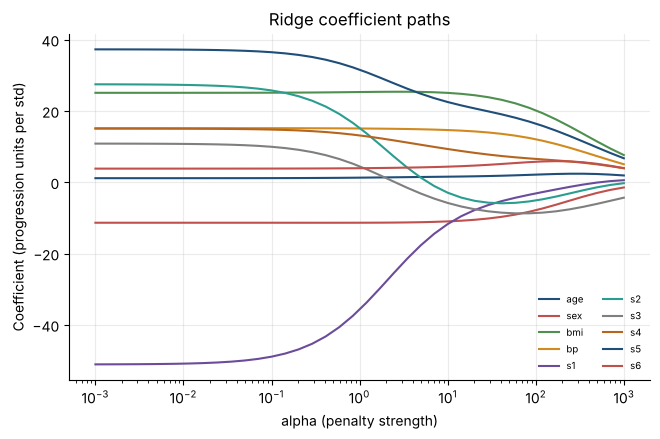

In [11]:
alphas = np.logspace(-3, 3, 40)
paths = np.array([Ridge(alpha=a).fit(Xtr, y_train).coef_ for a in alphas])
names = feature_names(clone(pipe).fit(X_train, y_train))
plt.plot(alphas, paths)
plt.xscale("log"); plt.xlabel("alpha (penalty strength)"); plt.ylabel("Coefficient (progression units per std)")
plt.legend([n.split("__")[-1] for n in names], ncol=2, fontsize=7); plt.title("Ridge coefficient paths"); plt.show()

### Experiment 2: Ridge versus ordinary least squares under added collinearity

Add a noisy copy of `bmi` and compare cross validated RMSE of OLS and ridge.

In [12]:
from sklearn.model_selection import cross_val_score
def cv_rmse(model, X_data=None, y_data=None):
    scores = cross_val_score(model, X_data if X_data is not None else X_trainval,
                             y_data if y_data is not None else y_trainval,
                             cv=5, scoring="neg_root_mean_squared_error")
    return -scores.mean(), scores.std(ddof=1)
from sklearn.linear_model import LinearRegression
rng = np.random.default_rng(SEED)
X_dup = X_trainval.copy()
X_dup["bmi_copy"] = X_dup["bmi"] + rng.normal(0, 0.002, len(X_dup))
for name, model in [("OLS", LinearRegression()), ("Ridge alpha=10", Ridge(alpha=10))]:
    mean, std = cv_rmse(make_model_pipeline(X_dup, model), X_dup)
    print(f"{name}: CV RMSE {mean:.2f} +- {std:.2f}")

OLS: CV RMSE 55.23 +- 3.88
Ridge alpha=10: CV RMSE 55.07 +- 4.19


### Experiment 3: Why scaling matters

Fit ridge with and without scaling on a version of the data where one feature is multiplied by 1000. The penalty is not scale invariant.

In [13]:
from sklearn.model_selection import cross_val_score
def cv_rmse(model, X_data=None, y_data=None):
    scores = cross_val_score(model, X_data if X_data is not None else X_trainval,
                             y_data if y_data is not None else y_trainval,
                             cv=5, scoring="neg_root_mean_squared_error")
    return -scores.mean(), scores.std(ddof=1)
X_big = X_trainval.copy()
X_big["bmi"] = X_big["bmi"] * 1000
for scaled in [True, False]:
    mean, std = cv_rmse(make_model_pipeline(X_big, Ridge(alpha=1.0), scale=scaled), X_big)
    print(f"scaled={scaled}: CV RMSE {mean:.2f} +- {std:.2f}")

scaled=True: CV RMSE 55.01 +- 4.15
scaled=False: CV RMSE 57.58 +- 3.24


### Exercises for learners

1. Repeat the notebook with `SEED = 7` and report how much the headline metric changes.
2. Add one more feature or remove one and explain the change using cross validation.
3. Replace the validation sweep with `GridSearchCV` and compare the chosen value.

## 14. Research Discussion

Hoerl and Kennard motivate ridge for near collinear predictors, and our coefficient path shows the smooth shrinkage they describe. Efron et al. analyse lasso type paths on the same patients, which the lasso notebook picks up.

**Dataset and method differences.** The papers above use other datasets, other splits and often other implementations. We do not claim that our numbers agree or disagree with them. What this notebook can show is whether the behaviour described in the paper (for example the effect of a parameter) appears on our data.

**Possible improvements.** Select alpha with `RidgeCV` and nested cross validation, and report intervals with a bootstrap.

**Research limitations.** One dataset, one split seed for the headline number, and small test sets for the UCI data. Cross validation spread is reported to show how unstable a single split can be.

## 15. Summary and Further Reading

**Key takeaways**

- Ridge shrinks but does not select.
- Scale features first.
- Tune alpha on validation or cross validation data.

**Use cases.** Many correlated predictors, small samples, stable scoring models.

**Limitations.** No feature selection, linear only.

**Recommended next notebook.** Lasso Regression.

**Further reading.** See `references.md` in this folder and the library documentation for the classes used above.